In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import os
print(os.getcwd())

c:\Users\Lenovo\Documents\Gender_Classification


In [3]:
import zipfile
zip_path = r"c:\Users\Lenovo\Documents\Gender_Classification\archive.zip"
with zipfile.ZipFile(zip_path,'r')as zipref:
    zipref.extractall('class')

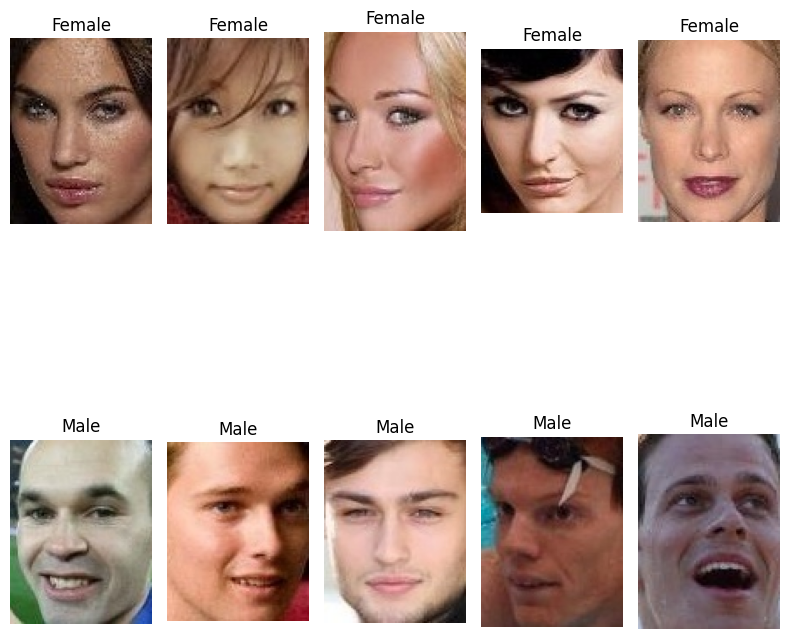

In [28]:
from PIL import Image
gender_path = {
    "Female": r"c:\Users\Lenovo\Documents\Gender_Classification\class\gender\female",
    "Male": r"c:\Users\Lenovo\Documents\Gender_Classification\class\gender\male"
}
position = 1
plt.figure(figsize=(8,10))
for gender,path in gender_path.items():
    files = os.listdir(path)[:5]
    for i,file in enumerate(files):
        img_path = os.path.join(path,file)
        img = Image.open(img_path)
        plt.subplot(2,5,position)
        plt.imshow(img)
        plt.title(gender)
        plt.axis('off')
        position+=1
plt.tight_layout()
plt.show()

In [29]:
total = 0
for i in gender_path.values():
    total+=len(os.listdir(i))
print("Total Images:",total)

Total Images: 20000


In [39]:
import tensorflow as tf

df = tf.keras.utils.image_dataset_from_directory(
    r"c:\Users\Lenovo\Documents\Gender_Classification\class\gender",
    image_size=(128, 128),
    batch_size=16,
    shuffle=True,
    seed=42
)


Found 20000 files belonging to 2 classes.


In [40]:
x = []
y = []
for images,labels in (df):
    x.extend(images.numpy()/255.0)
    y.extend(labels.numpy())
x = np.array(x)
y = np.array(y)

In [43]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.20,random_state=42,stratify=y)

In [46]:
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers

model = Sequential([
    layers.Conv2D(32,(3,3),activation='relu',input_shape=(128,128,3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64,(3,3),activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128,(3,3),activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.GlobalAveragePooling2D(),
    layers.Dense(256,activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1,activation='sigmoid')
])

In [47]:
model.compile(optimizer='adam',loss=['binary_crossentropy'],metrics=['accuracy'])

In [48]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor = 'val_loss',
    patience=10,
    verbose=1,
    start_from_epoch=0,
    restore_best_weights=True
)

In [49]:
history = model.fit(
    x_train,
    y_train,
    epochs=60,
    callbacks=[early_stopping],
    validation_split = 0.25,
    batch_size = 30
)

Epoch 1/60
400/400 ━━━━━━━━━━━━━━━━━━━━ 70s 165ms/step - accuracy: 0.5157 - loss: 0.6919 - val_accuracy: 0.5200 - val_loss: 0.6865
Epoch 2/60
400/400 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - accuracy: 0.6406 - loss: 0.6310 - val_accuracy: 0.7145 - val_loss: 0.5686
Epoch 3/60
400/400 ━━━━━━━━━━━━━━━━━━━━ 50s 125ms/step - accuracy: 0.7438 - loss: 0.5246 - val_accuracy: 0.7730 - val_loss: 0.4894
Epoch 4/60
400/400 ━━━━━━━━━━━━━━━━━━━━ 279s 698ms/step - accuracy: 0.8181 - loss: 0.4087 - val_accuracy: 0.8385 - val_loss: 0.3878
Epoch 5/60
400/400 ━━━━━━━━━━━━━━━━━━━━ 48s 121ms/step - accuracy: 0.8682 - loss: 0.3164 - val_accuracy: 0.8780 - val_loss: 0.3001
Epoch 6/60
400/400 ━━━━━━━━━━━━━━━━━━━━ 49s 122ms/step - accuracy: 0.8857 - loss: 0.2720 - val_accuracy: 0.8947 - val_loss: 0.2489
Epoch 7/60
400/400 ━━━━━━━━━━━━━━━━━━━━ 96s 241ms/step - accuracy: 0.9034 - loss: 0.2387 - val_accuracy: 0.8988 - val_loss: 0.2388
Epoch 8/60
400/400 ━━━━━━━━━━━━━━━━━━━━ 54s 135ms/step - accuracy: 0.9104 - loss: 

In [51]:
model.save("Gender_model1.keras")

In [50]:
test_loss,test_accuracy   = model.evaluate(x_test,y_test)
print(f"Test Accuracy: {test_accuracy}")

125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.9390 - loss: 0.1595
Test Accuracy: 0.9390000104904175


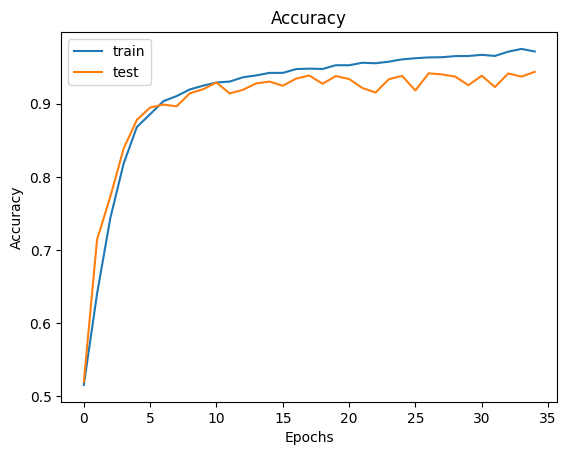

In [52]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(['train','test'],loc='upper left')
plt.show()

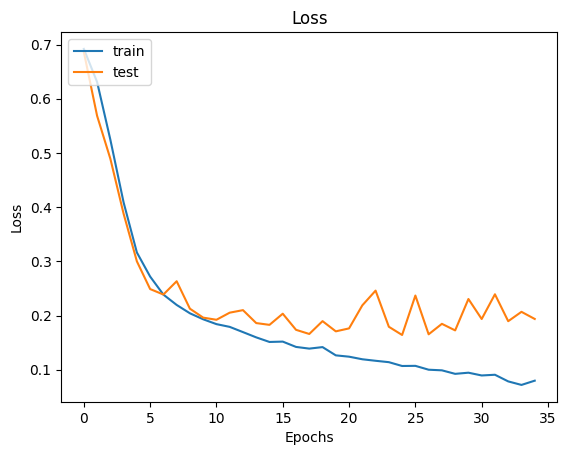

In [53]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(['train','test'],loc='upper left')
plt.show()

In [54]:
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

img = load_img("male.webp", target_size=(128, 128))

img_array = img_to_array(img) / 255.0

img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
[[0.95544034]]


In [59]:
print(df.class_names)

['female', 'male']
